--- 1. S05_01: Introducción a NumPy para Operaciones de Reservas ---
Ingresos por cada reserva: [340. 770. 285. 600. 300.]
Ingreso total estimado: 2295.0
Ingreso medio: 459.0

--- 2. S05_02: Álgebra Lineal aplicada a Tarifas y Ocupación ---
Ingresos calculados por bloque con producto matricial: [220 440]

--- 3. S05_03: Descenso del Gradiente aplicado a la Ocupación ---
Parámetros óptimos aprendidos -> Peso (w): 15.0248, Sesgo (b): 6.9106

--- 4. S05_04 & S05_05: Estadística Descriptiva y Correlación de Pearson ---
Coeficiente de Correlación de Pearson (Precio vs Noches): -0.2946

--- 5. S05_06: Operaciones CRUD en Base de Datos (SQLite) ---
Registros en la BD SQLite: [(1, 'directo', 3, 90.0)]

--- 6. S05_07: RETO DE OCUPACIÓN (Análisis Completo para TurisData) ---
Ecuación del Reto de Ocupación: Ocupación = 1.41 * Antelación + 31.22


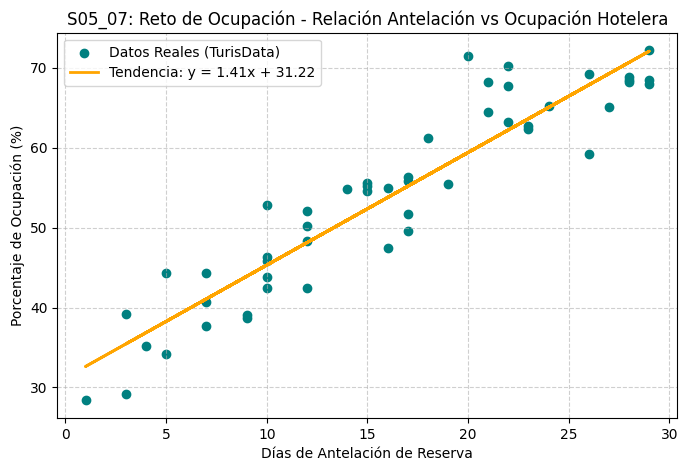

[OK] Gráfico del Reto de Ocupación (S05_07) generado y guardado correctamente.


In [2]:

# =====================================================================
# SPRINT 05: MATEMÁTICAS EN CÓDIGO (TURISDATA CANARIAS)
# Cuaderno unificado para Google Colab que cubre todos los ejercicios (S05_01 a S05_07)
# =====================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("--- 1. S05_01: Introducción a NumPy para Operaciones de Reservas ---")
precios = np.array([85.0, 110.0, 95.0, 120.0, 150.0])
noches = np.array([4, 7, 3, 5, 2])
ingresos_por_reserva = precios * noches
print("Ingresos por cada reserva:", ingresos_por_reserva)
print("Ingreso total estimado:", np.sum(ingresos_por_reserva))
print("Ingreso medio:", np.mean(ingresos_por_reserva))

print("\n--- 2. S05_02: Álgebra Lineal aplicada a Tarifas y Ocupación ---")
matriz_habitaciones = np.array([[2, 1], [4, 2]]) # [Individuales, Dobles]
vector_tarifas = np.array([60, 100])
ingresos_bloque = np.dot(matriz_habitaciones, vector_tarifas)
print("Ingresos calculados por bloque con producto matricial:", ingresos_bloque)

print("\n--- 3. S05_03: Descenso del Gradiente aplicado a la Ocupación ---")
np.random.seed(42)
X = np.array([1, 2, 3, 4, 5], dtype=float) # Antelación en días (normalizada)
y = np.array([20, 40, 50, 70, 80], dtype=float) # % de ocupación real

w = 0.0
b = 0.0
alpha = 0.01
epochs = 1000
n = len(X)

for epoch in range(epochs):
    y_pred = w * X + b
    dw = (-2/n) * np.sum(X * (y - y_pred))
    db = (-2/n) * np.sum(y - y_pred)
    w -= alpha * dw
    b -= alpha * db

print(f"Parámetros óptimos aprendidos -> Peso (w): {w:.4f}, Sesgo (b): {b:.4f}")

print("\n--- 4. S05_04 & S05_05: Estadística Descriptiva y Correlación de Pearson ---")
correlacion = np.corrcoef(precios, noches)[0, 1]
print(f"Coeficiente de Correlación de Pearson (Precio vs Noches): {correlacion:.4f}")

print("\n--- 5. S05_06: Operaciones CRUD en Base de Datos (SQLite) ---")
import sqlite3
conn = sqlite3.connect(":memory:")
cursor = conn.cursor()
cursor.execute("CREATE TABLE reservas (id_reserva INTEGER PRIMARY KEY, canal TEXT, noches INTEGER, precio_noche REAL)")
cursor.execute("INSERT INTO reservas (canal, noches, precio_noche) VALUES ('directo', 3, 90.0)")
conn.commit()
cursor.execute("SELECT * FROM reservas")
print("Registros en la BD SQLite:", cursor.fetchall())
conn.close()

print("\n--- 6. S05_07: RETO DE OCUPACIÓN (Análisis Completo para TurisData) ---")
# Simulación del dataset completo del reto de ocupación hotelera
np.random.seed(107)
dias_antelacion = np.random.randint(1, 30, size=50)
ocupacion_real = 30 + 1.5 * dias_antelacion + np.random.normal(0, 5, size=50)

# Cálculo de la línea de tendencia por mínimos cuadrados ordinarios (OLS)
m, c = np.polyfit(dias_antelacion, ocupacion_real, 1)
print(f"Ecuación del Reto de Ocupación: Ocupación = {m:.2f} * Antelación + {c:.2f}")

# Generar gráfico del Reto de Ocupación
plt.figure(figsize=(8, 5))
plt.scatter(dias_antelacion, ocupacion_real, color='teal', label='Datos Reales (TurisData)')
plt.plot(dias_antelacion, m * dias_antelacion + c, color='orange', linewidth=2, label=f'Tendencia: y = {m:.2f}x + {c:.2f}')
plt.title('S05_07: Reto de Ocupación - Relación Antelación vs Ocupación Hotelera')
plt.xlabel('Días de Antelación de Reserva')
plt.ylabel('Porcentaje de Ocupación (%)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.savefig('reto_ocupacion_grafico.png')
plt.show()
print("[OK] Gráfico del Reto de Ocupación (S05_07) generado y guardado correctamente.")